# Notebook 15 – Before vs After Analysis



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

raw = pd.DataFrame({
 'ID':[1,2,3,4,4,5,6,7,8,9],
 'Age':[22,29,np.nan,35,35,41,28,33,120,26],
 'Salary':[25000,38000,45000,np.nan,np.nan,60000,35000,52000,1000000,31000],
 'City':['Hassan','Bengaluru','Mysuru','Hassan','Hassan',None,'bengaluru','Mysuru','Hassan','Bengaluru'],
 'Purchased':[0,1,0,1,1,0,0,1,1,0]
})
print('Original dataset:')
print(raw)

Original dataset:
   ID    Age     Salary       City  Purchased
0   1   22.0    25000.0     Hassan          0
1   2   29.0    38000.0  Bengaluru          1
2   3    NaN    45000.0     Mysuru          0
3   4   35.0        NaN     Hassan          1
4   4   35.0        NaN     Hassan          1
5   5   41.0    60000.0       None          0
6   6   28.0    35000.0  bengaluru          0
7   7   33.0    52000.0     Mysuru          1
8   8  120.0  1000000.0     Hassan          1
9   9   26.0    31000.0  Bengaluru          0


## Preprocessing Demonstration (run before the comparisons)

This notebook compares a **descriptive, full-dataset cleaning example**, not a production train/test workflow. For ML evaluation, split first and fit learned imputation, capping, scaling, and encoding rules on **training data only**.

In [5]:
clean = raw.drop_duplicates().copy()
clean['City'] = clean['City'].str.strip().str.title().fillna('Unknown')
clean['Age'] = clean['Age'].fillna(clean['Age'].median())
clean['Salary'] = clean['Salary'].fillna(clean['Salary'].median())
# Aged 120 is invalid for this example's employee policy, not simply an extreme.
clean.loc[~clean['Age'].between(18, 90), 'Age'] = clean.loc[clean['Age'].between(18, 90), 'Age'].median()
# Demonstration policy: cap unusually high salaries at the 95th percentile.
clean['Salary'] = clean['Salary'].clip(upper=clean['Salary'].quantile(0.95))
clean['Age'] = clean['Age'].astype(float)
clean['Salary_Standardized'] = StandardScaler().fit_transform(clean[['Salary']])
clean = pd.get_dummies(clean, columns=['City'], dtype=int)
print('After preprocessing:')
print(clean)

After preprocessing:
   ID   Age    Salary  Purchased  Salary_Standardized  City_Bengaluru  \
0   1  22.0   25000.0          0            -0.439876               0   
1   2  29.0   38000.0          1            -0.369036               1   
2   3  31.0   45000.0          0            -0.330891               0   
3   4  35.0   41500.0          1            -0.349963               0   
5   5  41.0   60000.0          0            -0.249152               0   
6   6  28.0   35000.0          0            -0.385383               1   
7   7  33.0   52000.0          1            -0.292746               0   
8   8  30.0  624000.0          1             2.824228               0   
9   9  26.0   31000.0          0            -0.407181               1   

   City_Hassan  City_Mysuru  City_Unknown  
0            1            0             0  
1            0            0             0  
2            0            1             0  
3            1            0             0  
5            0            0 

## 1. Shape

### Definition
Shape describes the number of rows and columns. Removing duplicate rows can reduce row count. Encoding can increase column count. Compare both dimensions to understand changes.

### Business Example
A customer file may contain repeated rows. Cleaning removes exact copies. Encoding a city column creates multiple indicator columns. The dataset shape changes for understandable reasons.

### AI/ML Use
Model input shape determines sample count and feature count. Row loss should be justified. Extra encoded columns are expected. Compare shapes before training.

### Python Example

In [7]:
print("Before:", raw.shape, "After:", clean.shape)

Before: (10, 5) After: (9, 9)


### Explanation
The before shape includes duplicate rows and original text fields. The after shape has fewer rows and more encoded columns. These changes come from specific cleaning steps. Shape alone does not measure data quality.

## 2. Data Types

### Definition
Data types determine how operations work. Strings may be encoded into integers. Numeric features can become floating-point after imputation. Comparing types helps identify accidental conversions.

### Business Example
A city is stored as text before cleaning. It becomes several numeric indicator columns after encoding. Salary remains numeric. These changes help analytics systems process the data.

### AI/ML Use
ML models generally need numeric features. Correct types prevent calculation errors. Compare `dtypes` to verify expected transformations. IDs should not automatically be treated as predictive quantities.

### Python Example

In [9]:
print("Before types:\n", raw.dtypes)
print("After types:\n", clean.dtypes)

Before types:
 ID             int64
Age          float64
Salary       float64
City          object
Purchased      int64
dtype: object
After types:
 ID                       int64
Age                    float64
Salary                 float64
Purchased                int64
Salary_Standardized    float64
City_Bengaluru           int32
City_Hassan              int32
City_Mysuru              int32
City_Unknown             int32
dtype: object


### Explanation
Original City is an object column. After one-hot encoding, city indicators are integers. Age and salary remain numeric. The output is suitable for many sklearn estimators.

## 3. Missing Values

### Definition
Missing values are absent or unknown entries. Cleaning can fill them with chosen values. The number of missing cells should decrease. Filling choices must match the feature meaning.

### Business Example
A customer may omit city or salary. A business might use Unknown for city and median for salary. The records are preserved. Missingness can still be informative and should be documented.

### AI/ML Use
Many models require complete numeric input. Imputation should be learned on training data in production. Missingness patterns may also predict the target. Do not assume mean imputation is always correct.

### Python Example

In [11]:
print("Before missing:\n", raw.isna().sum())
print("After missing:\n", clean.isna().sum())

Before missing:
 ID           0
Age          1
Salary       2
City         1
Purchased    0
dtype: int64
After missing:
 ID                     0
Age                    0
Salary                 0
Purchased              0
Salary_Standardized    0
City_Bengaluru         0
City_Hassan            0
City_Mysuru            0
City_Unknown           0
dtype: int64


### Explanation
The raw dataset contains missing age, salary, and city. The cleaned dataset has no missing values. Different strategies were used for numeric and categorical fields. The choices should be validated against business rules.

## 4. Duplicates

### Definition
Duplicate records may be exact copies or legitimate repeat events. Exact duplicates can distort counts. Dropping them changes the row count. Business keys are needed to decide what is truly duplicated.

### Business Example
A repeated employee export row is likely accidental. Two purchases by the same customer may both be genuine. The correct rule depends on transaction IDs and timestamps. Blind deletion can lose information.

### AI/ML Use
Duplicates can bias training distributions. They may also appear in both training and test sets. Deduplication is important before splitting. Check which rows were removed.

### Python Example

In [13]:
print("Before duplicates:", raw.duplicated().sum())
print("After duplicates:", clean.duplicated().sum())

Before duplicates: 1
After duplicates: 0


### Explanation
The repeated row is detected in the original dataset. It is removed before other transformations. The cleaned dataset has no exact duplicate rows. A real project should confirm that the duplicate is not a valid repeated event.

## 5. Outliers

### Definition
Outliers are unusually extreme values. Some are errors and others are valid. Treatment can include correction, capping, transformation, or retention. The decision should be documented.

### Business Example
An age of 120 may violate an employee policy. A very high salary could still be legitimate. The age is corrected using a stated rule. Salary is capped here only as a demonstration policy.

### AI/ML Use
Extreme values can distort scaling and certain models. Valid extremes may contain important signals. Treat errors differently from genuine events. Avoid automatic removal of every outlier.

### Python Example

In [15]:
print("Age > 90 before:", (raw["Age"] > 90).sum())
print("Age > 90 after:", (clean["Age"] > 90).sum())
print("Maximum salary before/after:", raw["Salary"].max(), clean["Salary"].max())

Age > 90 before: 1
Age > 90 after: 0
Maximum salary before/after: 1000000.0 623999.9999999997


### Explanation
The invalid age is no longer present. The highest salary is reduced by the chosen cap. These are different decisions for different reasons. A real salary cap should be agreed with domain experts.

## 6. Distributions

### Definition
A distribution shows where values are concentrated. Imputation and outlier treatment may change its shape. Compare histograms before and after. Large changes may mean important information was lost.

### Business Example
A salary dataset may have a long right tail. Capping reduces the extreme end. The median may stay similar. A histogram helps the business see the effect.

### AI/ML Use
Models may respond differently to skewed inputs. Visual comparison reveals distortions. Preprocessing should improve usability without hiding genuine patterns. Always review before and after.

### Python Example

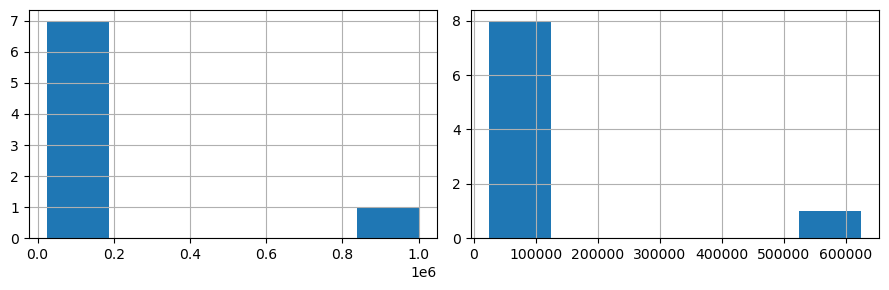

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
raw["Salary"].hist(ax=axes[0], bins=6, )
clean["Salary"].hist(ax=axes[1], bins=6, )
plt.tight_layout(); plt.show()

### Explanation
The left histogram includes an extreme salary. The right histogram shows the effect of capping and filling missing values. Both charts use the same original feature. Differences should be explained by the cleaning policy.

## 7. Categorical Values

### Definition
Categorical cleaning standardizes labels and handles missing categories. One-hot encoding turns categories into indicator columns. This can increase feature count. Review the accepted category list before encoding.

### Business Example
Bengaluru and bengaluru should represent the same city. Missing cities can be marked Unknown. Encoding creates columns for each city. This prevents inconsistent reporting.

### AI/ML Use
Models cannot directly use arbitrary city strings in many workflows. Consistent categories reduce noisy features. Unknown labels require a policy. High-cardinality features may need special handling.

### Python Example

In [19]:
print("Before categories:\n", raw["City"].value_counts(dropna=False))
print("After city columns:", [c for c in clean if c.startswith("City_")])

Before categories:
 City
Hassan       4
Bengaluru    2
Mysuru       2
None         1
bengaluru    1
Name: count, dtype: int64
After city columns: ['City_Bengaluru', 'City_Hassan', 'City_Mysuru', 'City_Unknown']


### Explanation
The raw city labels include inconsistent capitalization. The cleaned city labels are standardized before encoding. The new columns represent distinct categories. Missing city is represented by Unknown.

## 8. Numerical Ranges

### Definition
Numerical ranges show minimum and maximum values. Invalid entries and extreme values can enlarge ranges. Treatment may change these limits. Compare ranges to check whether the result makes sense.

### Business Example
An HR dataset should not contain impossible ages. A salary outlier can make charts difficult to read. Cleaning changes the range. The business must approve meaningful limits.

### AI/ML Use
Range affects scaling and distance-based models. Extreme values may dominate some transformations. Compare both before and after. Check that no new impossible values were introduced.

### Python Example

In [21]:
for col in ["Age", "Salary"]:
    print(col, "before:", (raw[col].min(), raw[col].max()), "after:", (clean[col].min(), clean[col].max()))

Age before: (22.0, 120.0) after: (22.0, 41.0)
Salary before: (25000.0, 1000000.0) after: (25000.0, 623999.9999999997)


### Explanation
The age maximum falls after invalid-value handling. Salary maximum decreases after capping. Minimum values remain reasonable. These changes reflect explicit rules rather than arbitrary deletion.

## 9. Feature Count

### Definition
Feature count is the number of model input columns. One-hot encoding often increases this number. Dropping identifier columns can reduce it. Count only predictors, not the target.

### Business Example
A company begins with age, salary, and city. City expands into several indicator fields. Customer ID is a tracking field rather than a predictor. The final feature count differs from the raw count.

### AI/ML Use
Too many features can increase complexity. Feature selection may be useful afterward. A larger feature count is not automatically better. Track which transformation created each feature.

### Python Example

In [23]:
before_features = raw.drop(columns=["ID", "Purchased"]).shape[1]
after_features = clean.drop(columns=["ID", "Purchased"]).shape[1]
print("Features before:", before_features, "after:", after_features)

Features before: 3 after: 7


### Explanation
ID and Purchased are excluded from feature counts. Categorical encoding increases the number of input columns. The feature count change is expected. The target is not accidentally included as a predictor.